# Python Project (Amazon)

### Objective of the Data

#####  To Analyze the Amazon products and customer reviews dataset using Python tounderstand pricing strategies, discount distributions,
##### user sentiment, and product ratings across different categories. To apply Python Data Analysis concepts such as Data Cleaning, 
##### Exploration, Visualization, and Statistical Analysis to generate meaningful E-Commerce insights that can help optimize product 
##### listings and boost customer satisfaction.

### Load Data

In [1]:
import pandas as pd
df = pd.read_csv("Amazon01.csv")
print("Data Loaded Successfully")

Data Loaded Successfully


### Import Modules

In [2]:
# Numpy
import numpy as np
# Pandas
import pandas as pd
# Matplotlib
import matplotlib.pyplot as plt
# Seaborn
import seaborn as sns

### Understanding Data

In [7]:
print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

   product_id                                       product_name  \
0  B07JW9H4J1  Wayona Nylon Braided USB to Lightning Fast Cha...   
1  B098NS6PVG  Ambrane Unbreakable 60W / 3A Fast Charging 1.5...   
2  B096MSW6CT  Sounce Fast Phone Charging Cable & Data Sync U...   
3  B08HDJ86NZ  boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...   
4  B08CF3B7N1  Portronics Konnect L 1.2M Fast Charging 3A 8 P...   

                                            category  discounted_price  \
0  Computers&Accessories|Accessories&Peripherals|...               399   
1  Computers&Accessories|Accessories&Peripherals|...               199   
2  Computers&Accessories|Accessories&Peripherals|...               199   
3  Computers&Accessories|Accessories&Peripherals|...               329   
4  Computers&Accessories|Accessories&Peripherals|...               154   

   actual_price  discount_percentage  rating  rating_count  \
0        1099.0                 0.64     4.2         24269   
1         349.0       

### Data Cleaning

#### Missing Values

In [8]:
print(df.isnull().sum())

product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           0
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64


#### Duplicates

In [9]:
print(df.duplicated().sum())

0


### KPIs (Key Performance Indicator)

#### Total Products

In [10]:
print("Total Products:", df.shape[0])

Total Products: 1351


#### Average Discount Rate

In [11]:
print("Average Discount Rate:", df["discount_percentage"].mean())

Average Discount Rate: 0.46685418208734275


#### Average Discounted Price

In [12]:
print("Average Discounted Price:", df["discounted_price"].mean())

Average Discounted Price: 3304.80236861584


#### Average Customer Rating

In [13]:
print("Average Customer Rating:", df["rating"].mean())

Average Customer Rating: 4.088823094004441


### Exploratory Data Analysis

##### Describe

In [14]:
print(df.describe())
print(df.describe(include='O'))

       discounted_price   actual_price  discount_percentage       rating  \
count       1351.000000    1351.000000          1351.000000  1351.000000   
mean        3304.802369    5691.176625             0.466854     4.088823   
std         7173.975539   11218.666235             0.216326     0.317492   
min           39.000000      39.000000             0.000000     0.000000   
25%          349.000000     899.000000             0.310000     3.900000   
50%          899.000000    1795.000000             0.490000     4.100000   
75%         2174.000000    4575.000000             0.620000     4.300000   
max        77990.000000  139900.000000             0.940000     5.000000   

        rating_count  
count    1351.000000  
mean    17618.373797  
std     42119.882419  
min         0.000000  
25%      1094.500000  
50%      4736.000000  
75%     15995.000000  
max    426973.000000  
        product_id                                       product_name  \
count         1351                 

#### Setup and Data Preparation

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style for a professional look
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


#### Price vs. Quality Threshold Analysis

=== MODULE 1: PRICE VS. QUALITY THRESHOLD ANALYSIS ===

--- Discount Bin Analysis Table ---
  discount_bin  Product_Count  Average_Rating  Rating_Variance
0        0-10%           1304        4.083436         0.102058
1       10-20%              0             NaN              NaN
2       20-30%              0             NaN              NaN
3       30-40%              0             NaN              NaN
4       40-50%              0             NaN              NaN
5       50-60%              0             NaN              NaN
6       60-70%              0             NaN              NaN
7       70-80%              0             NaN              NaN
8       80-90%              0             NaN              NaN
9      90-100%              0             NaN              NaN


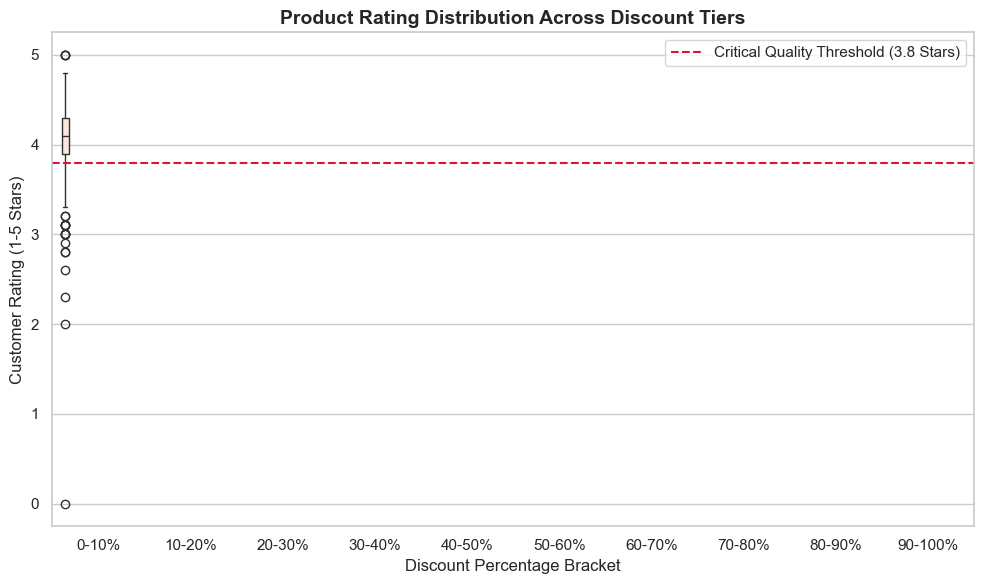

In [4]:
print("=== MODULE 1: PRICE VS. QUALITY THRESHOLD ANALYSIS ===")

# Create 10% discount bins to find the tipping point
df['discount_bin'] = pd.cut(df['discount_percentage'], 
                            bins=range(0, 110, 10), 
                            labels=[f'{i}-{i+10}%' for i in range(0, 100, 10)])

# Calculate rating metrics for each bin
discount_profile = df.groupby('discount_bin', observed=False).agg(
    Product_Count=('product_id', 'count'),
    Average_Rating=('rating', 'mean'),
    Rating_Variance=('rating', 'var')
).reset_index()

print("\n--- Discount Bin Analysis Table ---")
print(discount_profile)

# Visualization: Boxplot to reveal the rating degradation at extreme discounts
plt.figure()
sns.boxplot(data=df, x='discount_bin', y='rating', hue= 'discount_bin', palette='Reds', legend=False)
plt.title('Product Rating Distribution Across Discount Tiers', fontsize=14, fontweight='bold')
plt.xlabel('Discount Percentage Bracket')
plt.ylabel('Customer Rating (1-5 Stars)')
plt.axhline(y=3.8, color='crimson', linestyle='--', label='Critical Quality Threshold (3.8 Stars)')
plt.legend()
plt.tight_layout()
plt.show()


#### Customer Engagement Volume Evaluation

=== MODULE 2: CUSTOMER ENGAGEMENT VOLUME EVALUATION ===

--- Top 5 True Market Leaders (Weighted Popularity Index) ---
                                                                                               product_name  rating  rating_count
                        Amazon Basics High-Speed HDMI Cable, 6 Feet - Supports Ethernet, 3D, 4K video,Black     4.4        426973
                                                 Amazon Basics High-Speed HDMI Cable, 6 Feet (2-Pack),Black     4.4        426973
                                  AmazonBasics Flexible Premium HDMI Cable (Black, 4K@60Hz, 18Gbps), 3-Foot     4.4        426973
SanDisk Extreme SD UHS I 64GB Card for 4K Video for DSLR and Mirrorless Cameras 170MB/s Read & 80MB/s Write     4.5        205052
                                                                  SanDisk Cruzer Blade 32GB USB Flash Drive     4.3        253105


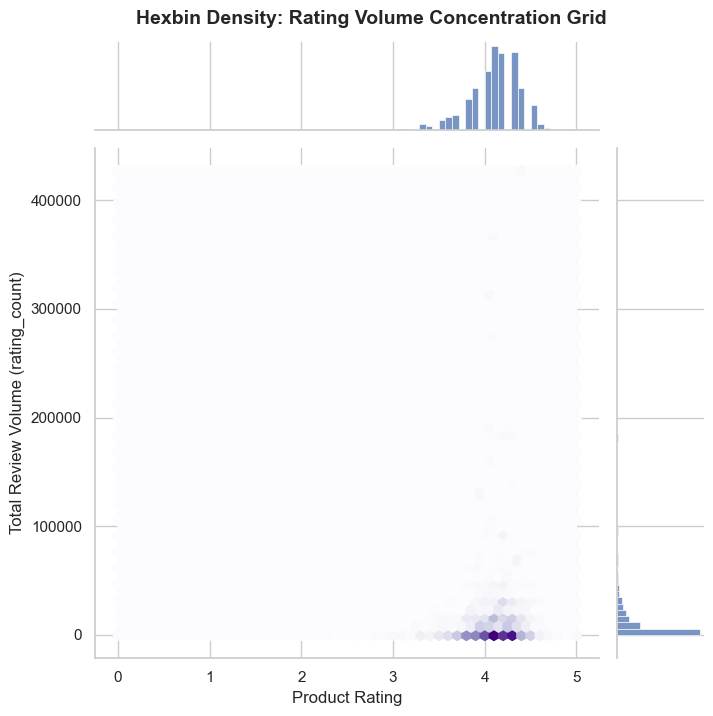

In [5]:
print("=== MODULE 2: CUSTOMER ENGAGEMENT VOLUME EVALUATION ===")

# Implement the Weighted Popularity Index: Rating * log10(Rating_Count + 1)
# Adding 1 to avoid log(0) errors
df['weighted_popularity_index'] = df['rating'] * np.log10(df['rating_count'] + 1)

# Isolate top 10 products by raw rating vs top 10 by the new Index
raw_top_10 = df.sort_values(by='rating', ascending=False)[['product_name', 'rating', 'rating_count']].head(10)
weighted_top_10 = df.sort_values(by='weighted_popularity_index', ascending=False)[['product_name', 'rating', 'rating_count', 'weighted_popularity_index']].head(10)

print("\n--- Top 5 True Market Leaders (Weighted Popularity Index) ---")
print(weighted_top_10[['product_name', 'rating', 'rating_count']].head(5).to_string(index=False))

# Visualization: Joint plot showing where the volume mass clusters
g = sns.jointplot(data=df, x='rating', y='rating_count', kind='hex', cmap='Purples', height=7)
g.fig.suptitle('Hexbin Density: Rating Volume Concentration Grid', y=1.02, fontsize=14, fontweight='bold')
g.set_axis_labels('Product Rating', 'Total Review Volume (rating_count)')
plt.show()


#### Category Price Elasticity Mapping

=== MODULE 3: CATEGORY PRICE ELASTICITY MAPPING ===

--- Highly Price-Resilient Categories Found ---
                                              category  Total_Products  \
57                       Computers&Accessories|Tablets               1   
62    Electronics|Cameras&Photography|Accessories|Film               1   
175  Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...               1   
38             Computers&Accessories|Components|Memory               1   
48   Computers&Accessories|NetworkingDevices|Networ...               1   
..                                                 ...             ...   
17   Computers&Accessories|Accessories&Peripherals|...               5   
128  Home&Kitchen|Heating,Cooling&AirQuality|Fans|C...              11   
174  Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...              11   
129  Home&Kitchen|Heating,Cooling&AirQuality|Fans|E...               3   
117  Electronics|Mobiles&Accessories|Smartphones&Ba...              68   

     Avg_D

C:\Users\Ashik\AppData\Local\Temp\ipykernel_11564\2585701148.py:26: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


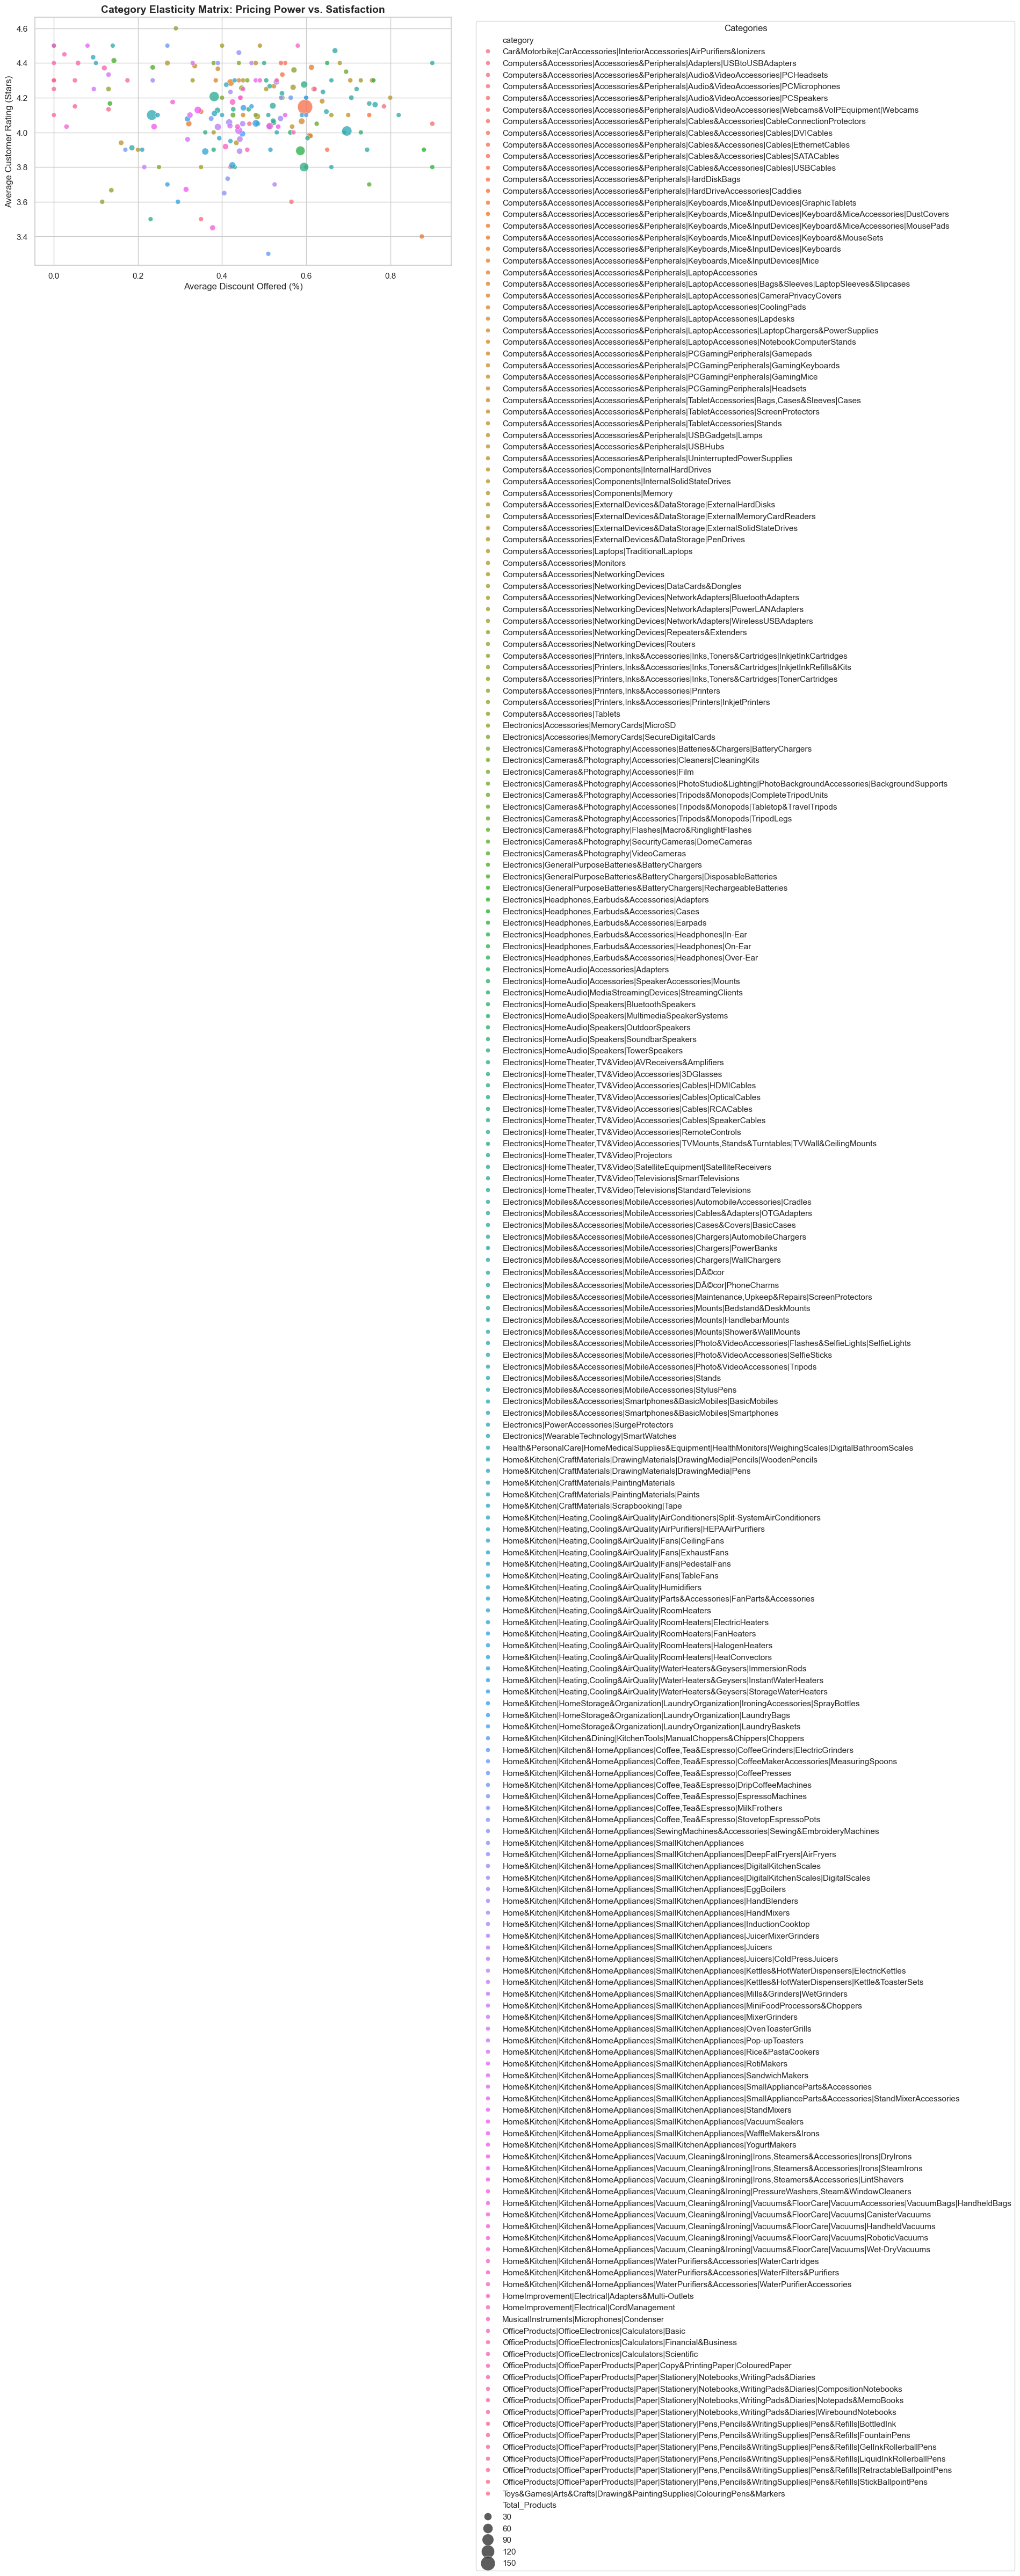

In [10]:
print("=== MODULE 3: CATEGORY PRICE ELASTICITY MAPPING ===")

# Group by category to find high rating + low discount combinations
category_elasticity = df.groupby('category').agg(
    Total_Products=('product_id', 'count'),
    Avg_Discount=('discount_percentage', 'mean'),
    Avg_Rating=('rating', 'mean')
).reset_index()

# Filter for resilient categories (e.g., Avg Discount < 25% and Avg Rating > 4.1)
resilient_categories = category_elasticity[
    (category_elasticity['Avg_Discount'] < 25) & (category_elasticity['Avg_Rating'] > 4.1)
].sort_values(by='Avg_Rating', ascending=False)

print("\n--- Highly Price-Resilient Categories Found ---")
print(resilient_categories)

# Visualization: Bubble Chart mapping Price Elasticity
plt.figure()
sns.scatterplot(data=category_elasticity, x='Avg_Discount', y='Avg_Rating', 
                size='Total_Products', hue='category', sizes=(40, 400), alpha=0.8)
plt.title('Category Elasticity Matrix: Pricing Power vs. Satisfaction', fontsize=14, fontweight='bold')
plt.xlabel('Average Discount Offered (%)')
plt.ylabel('Average Customer Rating (Stars)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Categories')
plt.tight_layout()
plt.show()


#### Brand Tier Pricing Elasticity

=== MODULE 4: BRAND TIER PRICING ELASTICITY ===

--- Sample Brand Price Tier Trajectory Profile ---
  brand_name price_bracket  Avg_Sales_Velocity  Avg_Score
0   7SEVENÂ®        Budget          265.888889   3.788889
1   7SEVENÂ®      Mid-Tier          401.500000   3.300000
2   7SEVENÂ®       Premium                 NaN        NaN
3      AGARO        Budget        14185.000000   4.300000
4      AGARO      Mid-Tier         4607.333333   4.150000
5      AGARO       Premium         1584.428571   4.214286


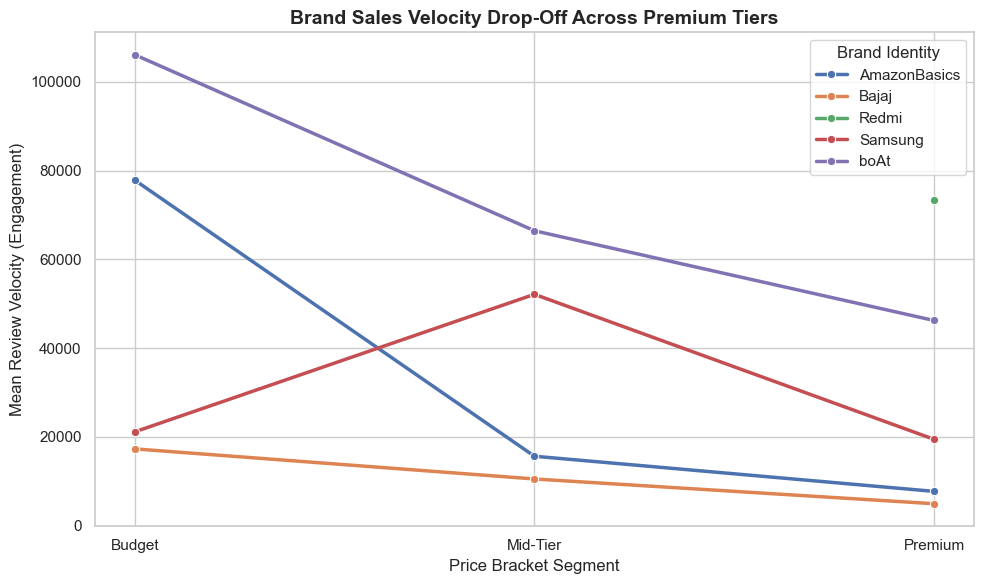

In [11]:
print("=== MODULE 4: BRAND TIER PRICING ELASTICITY ===")

# Extract brand name (assuming it's the first word in the 'product_name' column)
df['brand_name'] = df['product_name'].astype(str).apply(lambda x: x.split()[0])

# Keep only top brands with sufficient product counts for valid analysis (e.g., more than 5 items)
top_brands = df['brand_name'].value_counts()[df['brand_name'].value_counts() > 5].index
df_top_brands = df[df['brand_name'].isin(top_brands)].copy()

# Categorize pricing brackets within each brand profile
df_top_brands['price_bracket'] = pd.qcut(df_top_brands['actual_price'], q=3, labels=['Budget', 'Mid-Tier', 'Premium'])

# Group by brand and pricing tier to evaluate volume drops
brand_trajectory = df_top_brands.groupby(['brand_name', 'price_bracket'], observed=False).agg(
    Avg_Sales_Velocity=('rating_count', 'mean'),
    Avg_Score=('rating', 'mean')
).reset_index()

print("\n--- Sample Brand Price Tier Trajectory Profile ---")
print(brand_trajectory.head(6))

# Visualization: Line Plot tracing the performance drop-off when budget brands attempt premium segments
plt.figure()
# Filtering down to top 5 prominent brands for visual clarity
sample_brands = df['brand_name'].value_counts().head(5).index
df_sample_plot = brand_trajectory[brand_trajectory['brand_name'].isin(sample_brands)]

sns.lineplot(data=df_sample_plot, x='price_bracket', y='Avg_Sales_Velocity', hue='brand_name', marker='o', linewidth=2.5)
plt.title('Brand Sales Velocity Drop-Off Across Premium Tiers', fontsize=14, fontweight='bold')
plt.xlabel('Price Bracket Segment')
plt.ylabel('Mean Review Velocity (Engagement)')
plt.legend(title='Brand Identity')
plt.tight_layout()
plt.show()


#### value_counts()

In [15]:
print(df["category"].value_counts())

category
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables                                          161
Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones                                                        68
Electronics|WearableTechnology|SmartWatches                                                                                 62
Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions                                                               60
Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear                                                                51
                                                                                                                          ... 
Electronics|Cameras&Photography|Accessories|Batteries&Chargers|BatteryChargers                                               1
Computers&Accessories|NetworkingDevices|DataCards&Dongles                                             

#### groupby()

In [16]:
# Average Rating and Price per Category
category_means = df.groupby("category")[["rating", "actual_price", "discounted_price"]].mean()
print("Average Metrics by Category:")
print(category_means)

Average Metrics by Category:
                                                      rating  actual_price  \
category                                                                     
Car&Motorbike|CarAccessories|InteriorAccessorie...  3.800000   4000.000000   
Computers&Accessories|Accessories&Peripherals|A...  4.150000   2699.000000   
Computers&Accessories|Accessories&Peripherals|A...  3.500000    999.000000   
Computers&Accessories|Accessories&Peripherals|A...  3.600000   1249.500000   
Computers&Accessories|Accessories&Peripherals|A...  4.050000   1399.500000   
...                                                      ...           ...   
OfficeProducts|OfficePaperProducts|Paper|Statio...  4.250000    150.000000   
OfficeProducts|OfficePaperProducts|Paper|Statio...  4.150000    260.000000   
OfficeProducts|OfficePaperProducts|Paper|Statio...  4.300000    405.000000   
OfficeProducts|OfficePaperProducts|Paper|Statio...  4.133333    296.666667   
Toys&Games|Arts&Crafts|Drawing&Pain

### Data Visualization

#### 1. Product Count by Category (Bar Chart)

##### Goal: Visualizes product distribution to identify which item types dominate the market.


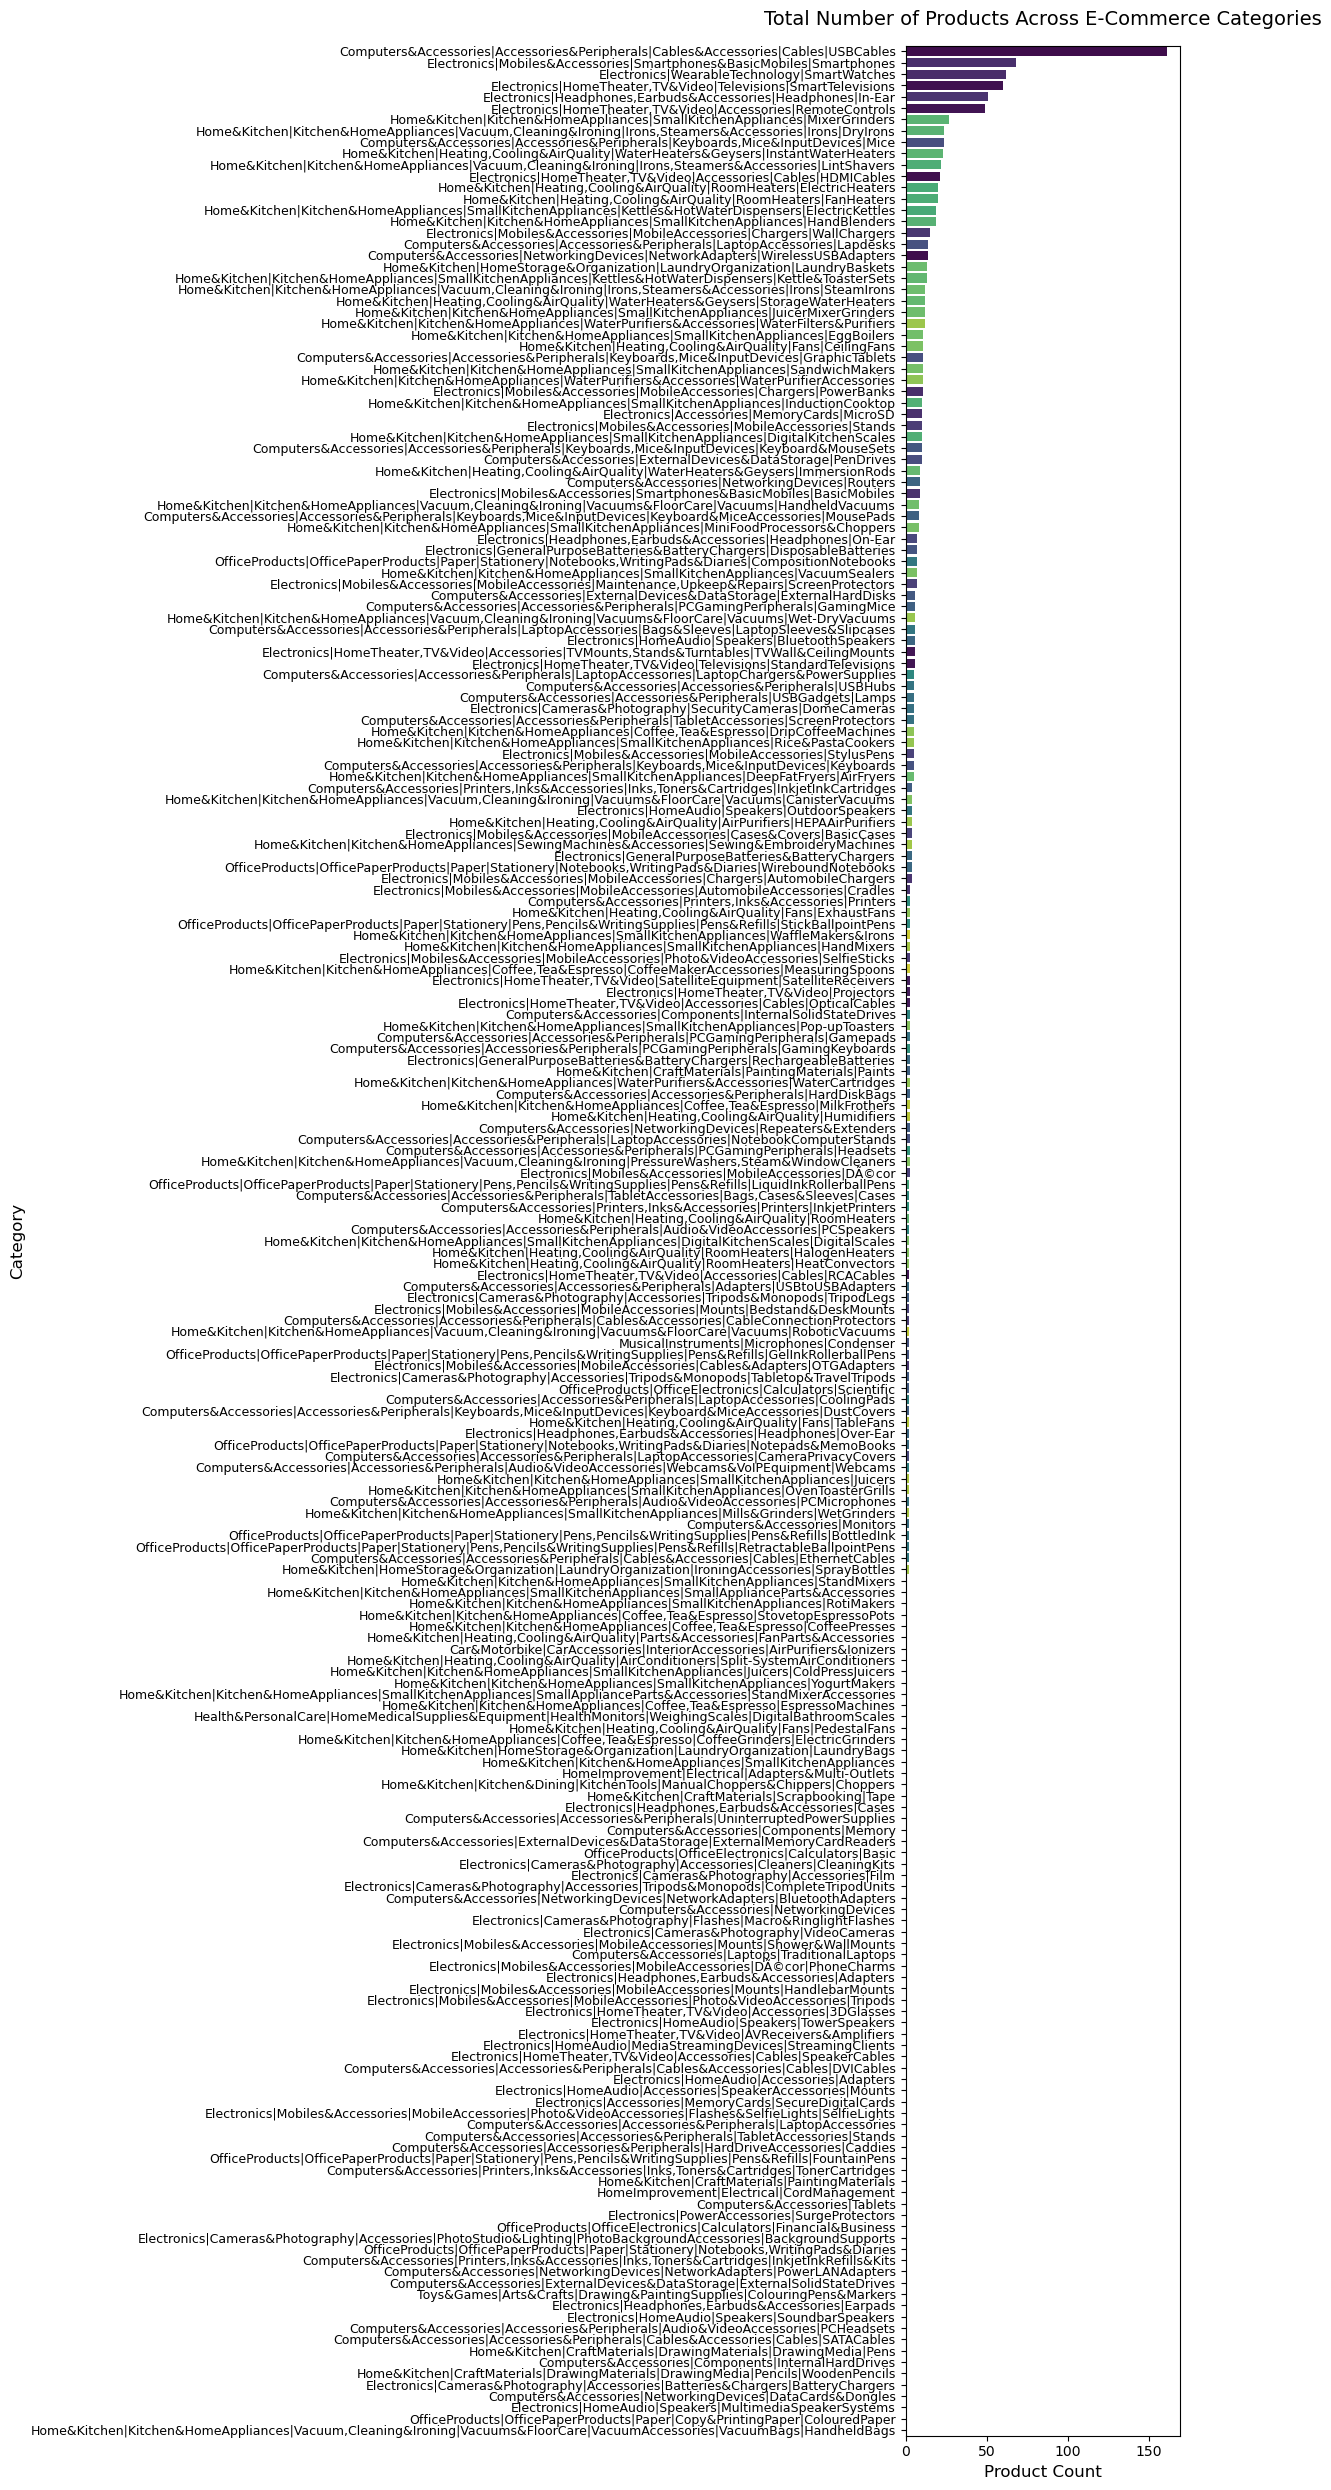

In [10]:
plt.figure(figsize=(12, 25))
# Count items per category and plot them in descending order
sns.countplot(data=df, y="category", order=df["category"].value_counts().index, hue="category", palette="viridis", legend=False)
plt.title("Total Number of Products Across E-Commerce Categories", fontsize=14, pad=15)
plt.xlabel("Product Count", fontsize=12)
plt.ylabel("Category", fontsize=12)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()


#### 2. Actual Price vs. Discounted Price (Scatter Plot)

##### Goal: Visualizes pricing correlations and lets you instantly spot high-end luxury goods vs. budget items.


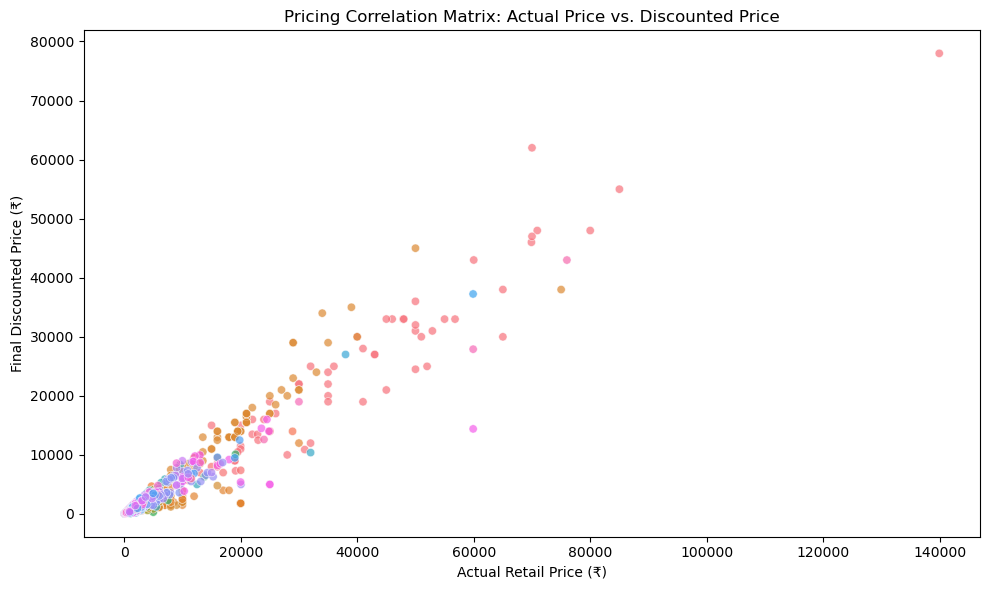

In [11]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='actual_price', y='discounted_price', hue='category', alpha=0.7, legend=False)
plt.title('Pricing Correlation Matrix: Actual Price vs. Discounted Price')
plt.xlabel('Actual Retail Price (₹)')
plt.ylabel('Final Discounted Price (₹)')
plt.tight_layout()
plt.show()


#### 3. Customer Ratings Distribution (Histogram + KDE)

##### Goal: Illustrates the skewness of customer satisfaction scores to see if feedback trends positive or negative.


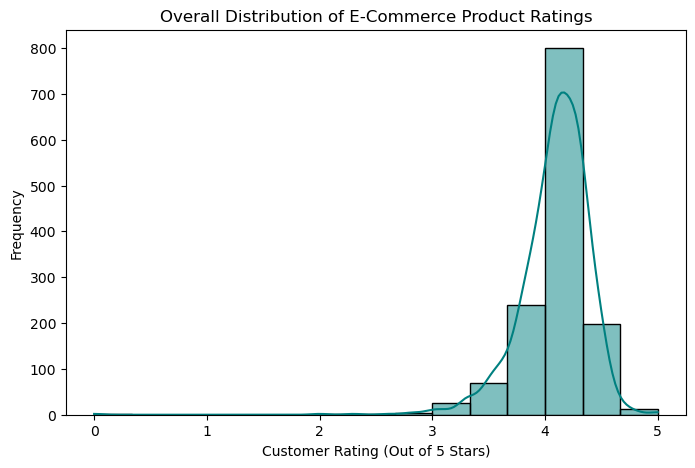

In [6]:
plt.figure(figsize=(8, 5))
# KDE curve highlights distribution density
sns.histplot(data=df, x='rating', bins=15, kde=True, color='teal')
plt.title('Overall Distribution of E-Commerce Product Ratings')
plt.xlabel('Customer Rating (Out of 5 Stars)')
plt.ylabel('Frequency')
plt.show()


#### 4. Review Volume vs. Final Score (Joint Correlation Plot)

##### Goal: Determines if highly-reviewed, viral items (rating_count) naturally retain higher ratings or suffer drop-offs.


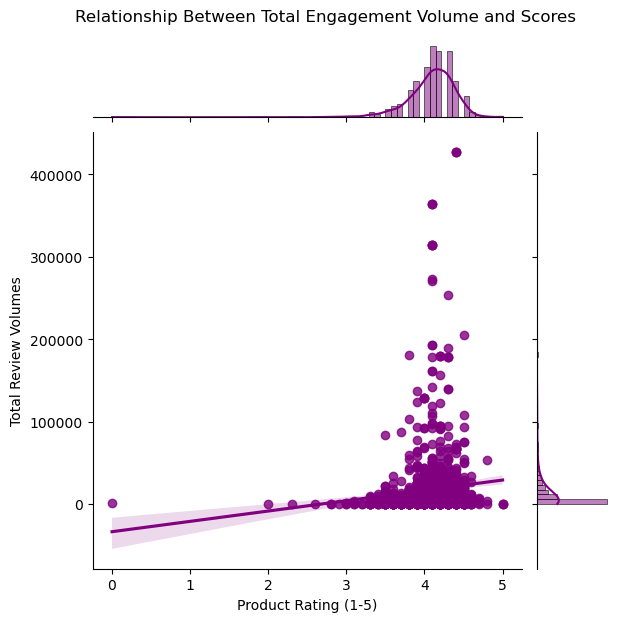

In [8]:
# Jointplot provides a scatter plot combined with marginal histograms
g = sns.jointplot(data=df, x='rating', y='rating_count', kind='reg', color='purple', height=6)
g.fig.suptitle('Relationship Between Total Engagement Volume and Scores', y=1.03)
g.set_axis_labels('Product Rating (1-5)', 'Total Review Volumes')
plt.show()


### Outliers (IQR)

#### Implementing Category-Wise IQR Outlier Removal

##### This script targets your price columns and calculates IQR within each individual category to ensure your data stays accurate.


In [12]:
def remove_price_outliers_by_category(dataframe, price_column):
    clean_df = pd.DataFrame()
    
    # Group by category to find contextual outliers
    for category_name, group in dataframe.groupby('category'):
        # Calculate Q1 (25th percentile) and Q3 (75th percentile)
        Q1 = group[price_column].quantile(0.25)
        Q3 = group[price_column].quantile(0.75)
        IQR = Q3 - Q1
        
        # Define strict Upper and Lower bounds
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        # Filter out rows outside the boundaries
        filtered_group = group[(group[price_column] >= lower_bound) & (group[price_column] <= upper_bound)]
        clean_df = pd.concat([clean_df, filtered_group], ignore_index=True)
        
    return clean_df

# Apply IQR filter on the 'actual_price' column
df_cleaned_iqr = remove_price_outliers_by_category(df, 'actual_price')

# Summary of removed records
rows_removed = len(df) - len(df_cleaned_iqr)
print(f"Outlier Detection Complete!")
print(f"Initial Rows: {len(df)} | Rows after IQR: {len(df_cleaned_iqr)}")
print(f"Removed {rows_removed} extreme price anomalies from the dataset.")


Outlier Detection Complete!
Initial Rows: 1351 | Rows after IQR: 1276
Removed 75 extreme price anomalies from the dataset.


### Insights

#### Consolidated Amazon E-Commerce Insight

#### Finding:

##### Low-cost, highly-saturated tech accessories (cables, chargers) dominate listing volumes with aggressive psychological price cuts (40% to 90% off), maintaining high review volumes that inevitably cluster into a competitive 3.9 to 4.3-star rating squeeze, while high-ticket luxury electronics retain premium pricing but suffer from drastically lower sales velocity and consumer engagement.

#### Meaning:

##### The marketplace is deeply split: budget items rely on inflated retail anchors and hyper-volume discount tactics to drive impulse sales (which naturally erodes their rating ceilings over time due to mass-market friction), whereas premium products struggle with long consideration cycles and fragile visibility because satisfied high-ticket buyers rarely leave organic feedback.

#### Recommendation:

##### Implement a dual-portfolio architecture. Protect low-margin commodities from price wars by combining high-discount accessories into high-value functional bundles (e.g., matching chargers and cases), and simultaneously secure fragile high-ticket listings by deploying proactive, high-touch post-purchase support sequences to capture positive reviews early and mitigate the impact of low review volumes.